# Chapter 11: Gaussian elimination

The code for this chapter from [*Matrices in Practice*](https://trgoodale.github.io/matrix-book/part-2/11-gaussian-elimination.html), by Tom Goodale.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/trgoodale/matrix-book/blob/main/code/python/11-gaussian-elimination.ipynb)

Run the cells in order, from the top: later cells use variables set in earlier ones. Change the numbers and run them again to see what happens. The code needs NumPy, SciPy and Matplotlib (and pandas in a few chapters), all of which Colab already has.

Code licensed under the [MIT licence](https://trgoodale.github.io/matrix-book/LICENSE.md).

### Code for Figure 11.1

This draws [Figure 11.1](https://trgoodale.github.io/matrix-book/part-2/11-gaussian-elimination.html#fig-ge-lines) in the chapter. You don't need it for the rest of the notebook.

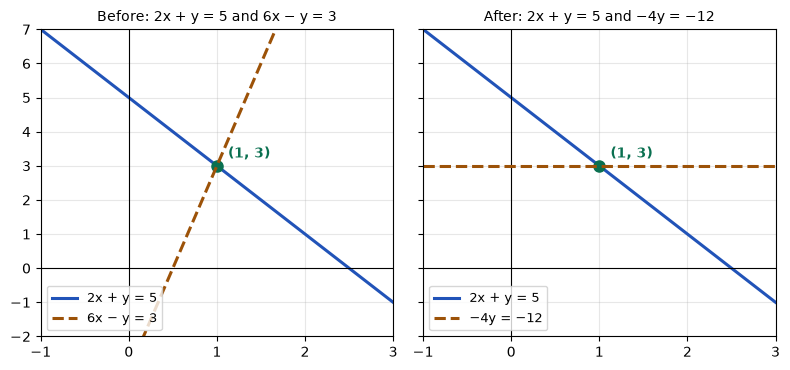

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(-1, 3, 2)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8), sharey=True)
for ax, title in zip(axes, ["Before: 2x + y = 5 and 6x − y = 3", "After: 2x + y = 5 and −4y = −12"]):
    ax.plot(t, 5 - 2 * t, color="#2153b8", lw=2.2, label="2x + y = 5")
    ax.plot(1, 3, "o", color="#0a7050", ms=8)
    ax.annotate("(1, 3)", (1, 3), xytext=(8, 6), textcoords="offset points", color="#0a7050", fontweight="bold")
    ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", lw=0.8)
    ax.set_xlim(-1, 3); ax.set_ylim(-2, 7); ax.set_xticks(range(-1, 4)); ax.grid(alpha=0.3)
    ax.set_title(title, fontsize=10)
axes[0].plot(t, 6 * t - 3, color="#9c5208", lw=2.2, ls="--", label="6x − y = 3")
axes[1].plot(t, 0 * t + 3, color="#9c5208", lw=2.2, ls="--", label="−4y = −12")
for ax in axes:
    ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

### Code for Figure 11.2

This draws [Figure 11.2](https://trgoodale.github.io/matrix-book/part-2/11-gaussian-elimination.html#fig-ge-cost) in the chapter. You don't need it for the rest of the notebook.

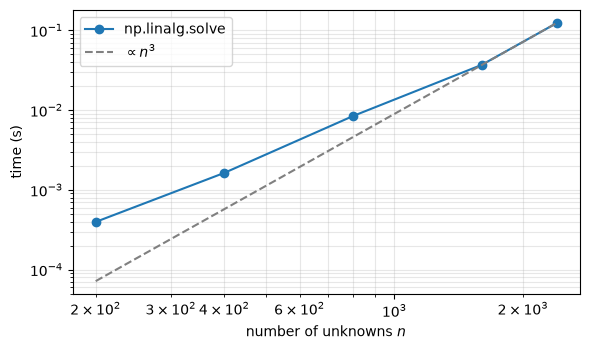

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

def best_time(f, repeats=3):
    """Shortest of several timings, to reduce noise."""
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
    return best

rng = np.random.default_rng(1)
sizes = [200, 400, 800, 1600, 2400]
times = []
for n in sizes:
    M = rng.standard_normal((n, n))
    v = rng.standard_normal(n)
    times.append(best_time(lambda: np.linalg.solve(M, v)))

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.loglog(sizes, times, "o-", label="np.linalg.solve")
ref = [times[-1] * (n / sizes[-1]) ** 3 for n in sizes]
ax.loglog(sizes, ref, "--", color="grey", label=r"$\propto n^3$")
ax.set_xlabel("number of unknowns $n$")
ax.set_ylabel("time (s)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## In code

The function below follows the method exactly: a loop over pivot columns, an inner loop over the rows below, then back substitution. It stops with an error if it meets a zero pivot. [Chapter 25](https://trgoodale.github.io/matrix-book/part-5/25-pivoting.html) adds row swaps.

In [3]:
import numpy as np

def gaussian_elimination(A, b):
    """Solve Ax = b by Gaussian elimination without pivoting."""
    A = np.array(A, dtype=float)       # work on copies
    b = np.array(b, dtype=float)
    n = len(b)

    # Forward elimination
    for k in range(n - 1):
        if A[k, k] == 0:
            raise ValueError(f"Zero pivot in row {k + 1}: a row swap is needed")
        for i in range(k + 1, n):
            m = A[i, k] / A[k, k]       # multiplier
            A[i, k:] -= m * A[k, k:]
            b[i] -= m * b[k]

    # Back substitution
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

A = [[2, 1, -1], [-3, -1, 2], [-2, 1, 2]]
b = [8, -11, -3]
print(gaussian_elimination(A, b))

[ 2.  3. -1.]


In practice, use the library solver, which adds pivoting and is far faster:

In [4]:
print(np.linalg.solve(A, b))

[ 2.  3. -1.]


## Exercises

The code exercises from the [end of the chapter](https://trgoodale.github.io/matrix-book/part-2/11-gaussian-elimination.html#sec-gaussian-elimination-exercises). Worked solutions are in the notebook `solutions-part-2.ipynb`, and in the [book's solutions](https://trgoodale.github.io/matrix-book/appendices/solutions-2.html#sec-solutions-gaussian-elimination).

### Exercise 6

Add a counter to the `gaussian_elimination` function that counts every multiplication, division, addition and subtraction. Run it on random systems with $n = 10, 20, 40, 80$, and compare the counts with $\tfrac{2}{3}n^3$.

In [5]:
# Your code here